In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv("Online Retail.csv", encoding="ISO-8859-1")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display the first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [4]:
# Check the number of rows and columns
df.shape

(541909, 8)

In [5]:
# Display column names
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [14]:
# Convert InvoiceDate into datetime format

df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    format='%d-%m-%Y %H:%M'
)

print("Date conversion successful!")

print(df['InvoiceDate'].head())

Date conversion successful!
0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]


In [15]:
df['Sales'] = df['Quantity'] * df['UnitPrice']

print("Sales column created successfully!")

Sales column created successfully!


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
 8   Sales        541909 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 63.7 MB


In [17]:
# Remove cancelled invoices
df = df[~df['InvoiceNo'].str.startswith('C')]

# Remove negative and zero quantities
df = df[df['Quantity'] > 0]

# Remove zero and negative prices
df = df[df['UnitPrice'] > 0]

# Recalculate sales
df['Sales'] = df['Quantity'] * df['UnitPrice']

print("Final data cleaning completed!")
print("Dataset shape:", df.shape)

Final data cleaning completed!
Dataset shape: (530104, 9)


In [18]:
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['Day'] = df['InvoiceDate'].dt.day

print("Date features created successfully!")

Date features created successfully!


In [19]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Sales,Year,Month,Day
count,530104.000000,530104,530104.000000,397884.000000,530104.000000,530104.000000,530104.000000,530104.000000
mean,10.542037,2011-07-04 20:16:05.225087,3.907625,15294.423453,20.121871,2010.921751,7.560611,15.020922
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000,2010.000000,1.000000,1.000000
25%,1.000000,2011-03-28 12:22:00,1.250000,13969.000000,3.750000,2011.000000,5.000000,7.000000
50%,3.000000,2011-07-20 12:58:00,2.080000,15159.000000,9.900000,2011.000000,8.000000,15.000000
75%,10.000000,2011-10-19 12:39:00,4.130000,16795.000000,17.700000,2011.000000,11.000000,22.000000
max,80995.000000,2011-12-09 12:50:00,13541.330000,18287.000000,168469.600000,2011.000000,12.000000,31.000000
std,155.524124,NaN,35.915681,1713.141560,270.356743,0.268563,3.508496,8.661560


In [20]:
# Reload the original dataset

df = pd.read_csv("Online Retail.csv", encoding="ISO-8859-1")

# Display original date values
print(df['InvoiceDate'].head(10))

0    01-12-2010 08:26
1    01-12-2010 08:26
2    01-12-2010 08:26
3    01-12-2010 08:26
4    01-12-2010 08:26
5    01-12-2010 08:26
6    01-12-2010 08:26
7    01-12-2010 08:28
8    01-12-2010 08:28
9    01-12-2010 08:34
Name: InvoiceDate, dtype: str


In [25]:
# Convert InvoiceDate using the correct date format

df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    format='%d-%m-%Y %H:%M'
)

# Create Sales column
df['Sales'] = df['Quantity'] * df['UnitPrice']

# Remove cancelled transactions
df = df[~df['InvoiceNo'].str.startswith('C')]

# Remove invalid quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

print("Data prepared successfully!")

Data prepared successfully!


In [26]:
# Extract date
df['Date'] = df['InvoiceDate'].dt.date

# Calculate daily sales
daily_sales = df.groupby('Date')['Sales'].sum().reset_index()

# Rename columns
daily_sales.columns = ['Date', 'Total_Sales']

print("Daily sales created successfully!")

daily_sales.head(10)

Daily sales created successfully!


,Date,Total_Sales
0,2010-12-01,58960.79
1,2010-12-02,47748.38
2,2010-12-03,46943.71
3,2010-12-05,31774.95
4,2010-12-06,54830.46
5,2010-12-07,99618.20
6,2010-12-08,45389.98
7,2010-12-09,53586.18
8,2010-12-10,59182.92
9,2010-12-12,17329.07


In [27]:
daily_sales.shape

(305, 2)

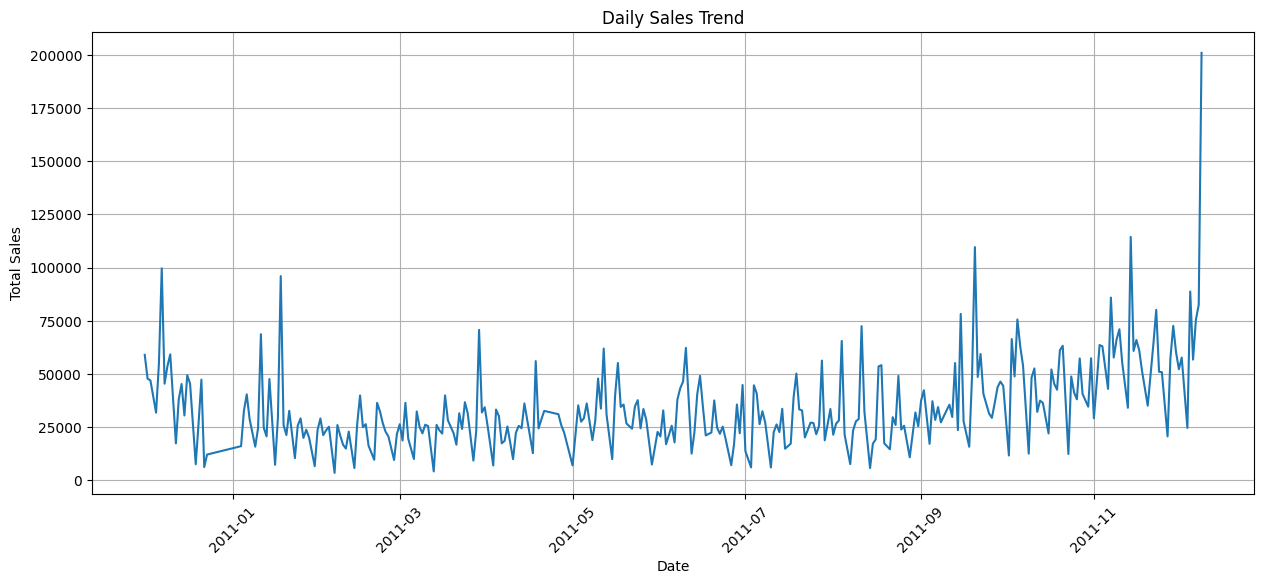

In [28]:
# Convert Date column into datetime
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])

# Plot daily sales
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales['Date'],
    daily_sales['Total_Sales']
)

plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [29]:
# Calculate monthly sales

df['Month_Year'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('Month_Year')['Sales'].sum()

monthly_sales

Month_Year
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Sales, dtype: float64

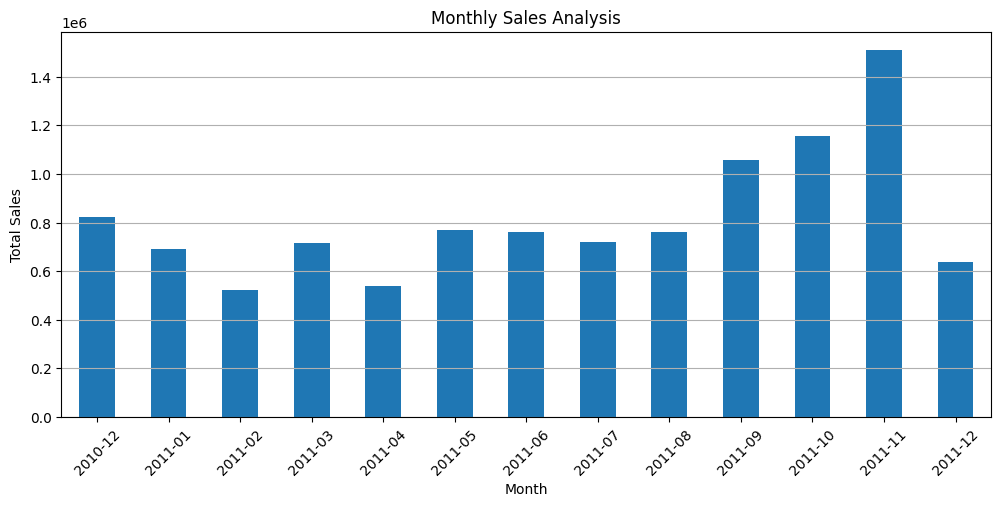

In [30]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='bar')

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

In [31]:
# Set Date as index
daily_sales = daily_sales.set_index('Date')

# Sort dates
daily_sales = daily_sales.sort_index()

# Check the date range
print("Start Date:", daily_sales.index.min())
print("End Date:", daily_sales.index.max())

# Display dataset
daily_sales.head()

Start Date: 2010-12-01 00:00:00
End Date: 2011-12-09 00:00:00


,Total_Sales
Date,
2010-12-01,58960.79
2010-12-02,47748.38
2010-12-03,46943.71
2010-12-05,31774.95
2010-12-06,54830.46


In [32]:
print("Missing values:")
print(daily_sales.isnull().sum())

print("Total daily records:", len(daily_sales))

Missing values:
Total_Sales    0
dtype: int64
Total daily records: 305


In [33]:
# Fill missing calendar dates with zero sales

daily_sales = daily_sales.asfreq('D', fill_value=0)

print("Continuous daily sales data created!")

print("Total records:", len(daily_sales))

print("Missing values:")
print(daily_sales.isnull().sum())

Continuous daily sales data created!
Total records: 374
Missing values:
Total_Sales    0
dtype: int64


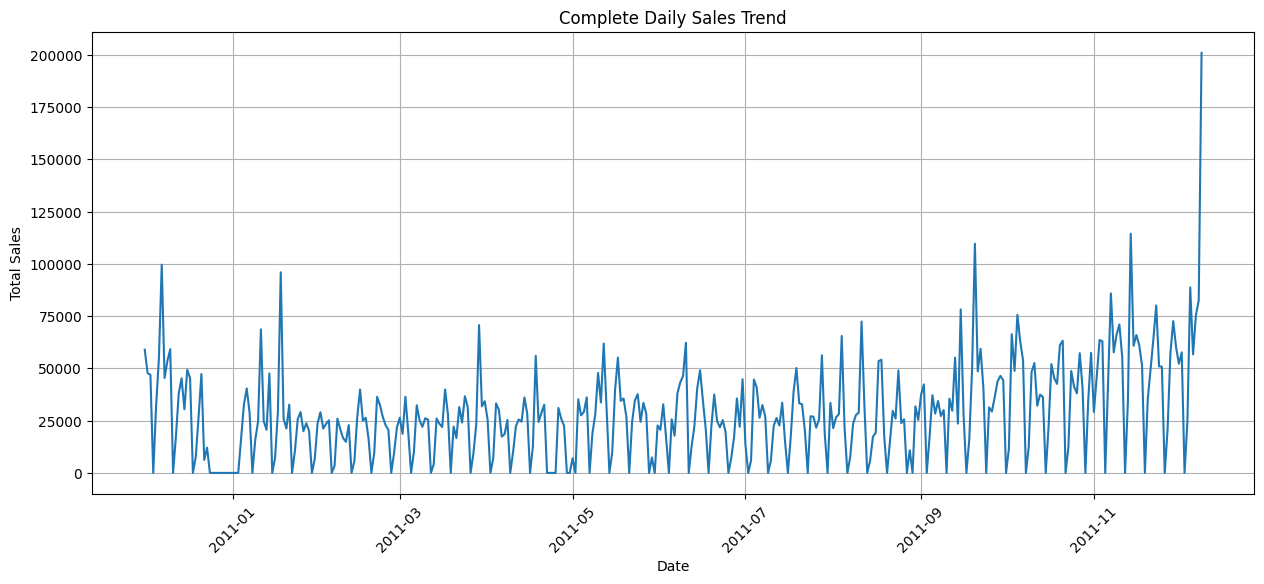

In [34]:
plt.figure(figsize=(15, 6))

plt.plot(daily_sales.index, daily_sales['Total_Sales'])

plt.title('Complete Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.grid(True)
plt.xticks(rotation=45)

plt.show()

In [35]:
# Create time-based features

daily_sales['Day'] = daily_sales.index.day
daily_sales['Month'] = daily_sales.index.month
daily_sales['Year'] = daily_sales.index.year
daily_sales['DayOfWeek'] = daily_sales.index.dayofweek

print("Forecasting features created!")

daily_sales.head()

Forecasting features created!


,Total_Sales,Day,Month,Year,DayOfWeek
Date,,,,,
2010-12-01,58960.79,1,12,2010,2
2010-12-02,47748.38,2,12,2010,3
2010-12-03,46943.71,3,12,2010,4
2010-12-04,0.00,4,12,2010,5
2010-12-05,31774.95,5,12,2010,6


In [36]:
# Create lag features

daily_sales['Lag_1'] = daily_sales['Total_Sales'].shift(1)

daily_sales['Lag_7'] = daily_sales['Total_Sales'].shift(7)

daily_sales['Lag_14'] = daily_sales['Total_Sales'].shift(14)

daily_sales['Lag_30'] = daily_sales['Total_Sales'].shift(30)

print("Lag features created successfully!")

daily_sales.head(15)

Lag features created successfully!


,Total_Sales,Day,Month,Year,DayOfWeek,Lag_1,Lag_7,Lag_14,Lag_30
Date,,,,,,,,,
2010-12-01,58960.79,1,12,2010,2,NaN,NaN,NaN,NaN
2010-12-02,47748.38,2,12,2010,3,58960.79,NaN,NaN,NaN
2010-12-03,46943.71,3,12,2010,4,47748.38,NaN,NaN,NaN
2010-12-04,0.00,4,12,2010,5,46943.71,NaN,NaN,NaN
2010-12-05,31774.95,5,12,2010,6,0.00,NaN,NaN,NaN
2010-12-06,54830.46,6,12,2010,0,31774.95,NaN,NaN,NaN
2010-12-07,99618.20,7,12,2010,1,54830.46,NaN,NaN,NaN
2010-12-08,45389.98,8,12,2010,2,99618.20,58960.79,NaN,NaN
2010-12-09,53586.18,9,12,2010,3,45389.98,47748.38,NaN,NaN


In [37]:
daily_sales = daily_sales.dropna()

print("Missing values removed!")
print("Final dataset shape:", daily_sales.shape)

Missing values removed!
Final dataset shape: (344, 9)


In [38]:
# Define input features
X = daily_sales[['Day', 'Month', 'Year', 'DayOfWeek',
                 'Lag_1', 'Lag_7', 'Lag_14', 'Lag_30']]

# Define target variable
y = daily_sales['Total_Sales']

# Split data chronologically (80% training, 20% testing)
split_index = int(len(daily_sales) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training and testing data created!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Training and testing data created!
X_train: (275, 8)
X_test: (69, 8)
y_train: (275,)
y_test: (69,)


In [39]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [40]:
# Train the Random Forest model

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [41]:
# Predict sales

y_pred = model.predict(X_test)

print("Sales prediction completed!")

print(y_pred[:10])

Sales prediction completed!
[22761.55651  39139.448805 37834.941905 35789.982115 37704.56126
 37277.967865   144.18295  19899.594495 60280.10557  40751.93909 ]


In [42]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 14151.37050702899
RMSE: 24127.46697953495
R2 Score: 0.40491347286187995


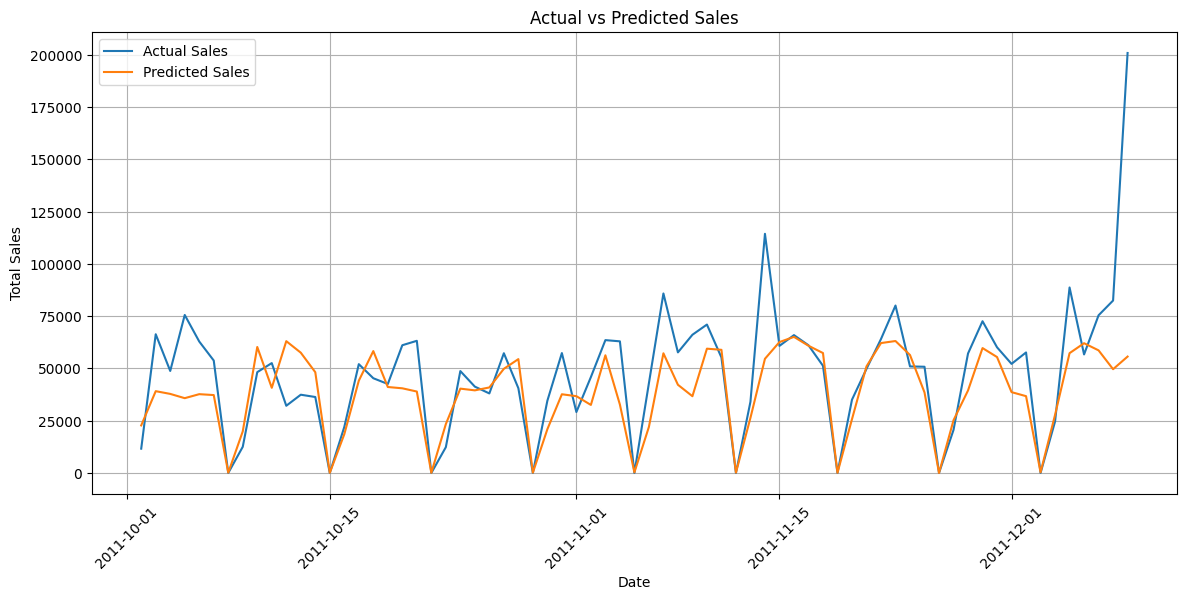

In [43]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test.values, label='Actual Sales')

plt.plot(y_test.index, y_pred, label='Predicted Sales')

plt.title('Actual vs Predicted Sales')

plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.legend()
plt.grid(True)

plt.xticks(rotation=45)

plt.show()

In [44]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
}, index=y_test.index)

comparison.head(15)

,Actual Sales,Predicted Sales
Date,,
2011-10-02,11634.53,22761.556510
2011-10-03,66376.82,39139.448805
2011-10-04,48810.65,37834.941905
2011-10-05,75593.63,35789.982115
2011-10-06,62891.19,37704.561260
2011-10-07,53790.70,37277.967865
2011-10-08,0.00,144.182950
2011-10-09,12524.40,19899.594495
2011-10-10,48239.18,60280.105570


In [45]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

print(importance)

     Feature  Importance
3  DayOfWeek    0.338728
5      Lag_7    0.295955
6     Lag_14    0.087792
4      Lag_1    0.081860
0        Day    0.074802
1      Month    0.069600
7     Lag_30    0.050516
2       Year    0.000746


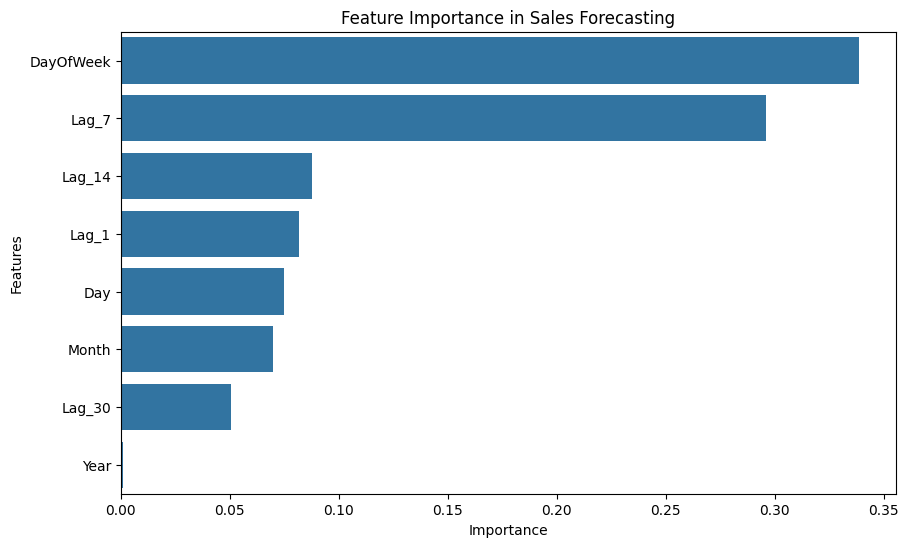

In [46]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance in Sales Forecasting')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

In [47]:
# Get the last available date
last_date = daily_sales.index.max()

# Store historical sales
sales_history = daily_sales['Total_Sales'].tolist()

# Create future predictions
future_predictions = []

for i in range(1, 8):

    next_date = last_date + pd.Timedelta(days=i)

    new_data = pd.DataFrame([{
        'Day': next_date.day,
        'Month': next_date.month,
        'Year': next_date.year,
        'DayOfWeek': next_date.dayofweek,
        'Lag_1': sales_history[-1],
        'Lag_7': sales_history[-7],
        'Lag_14': sales_history[-14],
        'Lag_30': sales_history[-30]
    }])

    prediction = model.predict(new_data)[0]

    future_predictions.append({
        'Date': next_date,
        'Predicted_Sales': prediction
    })

    sales_history.append(prediction)

future_df = pd.DataFrame(future_predictions)

print(future_df)

        Date  Predicted_Sales
0 2011-12-10       223.073950
1 2011-12-11     24431.099975
2 2011-12-12     58188.023475
3 2011-12-13     61833.987800
4 2011-12-14     62314.962600
5 2011-12-15     61430.799650
6 2011-12-16     57581.630500


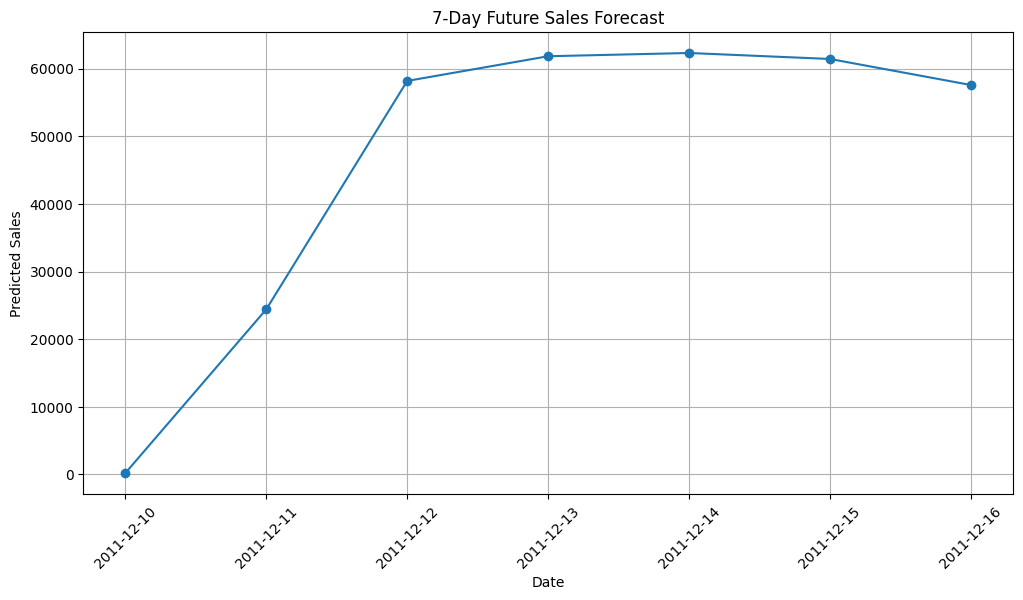

In [48]:
plt.figure(figsize=(12, 6))

plt.plot(
    future_df['Date'],
    future_df['Predicted_Sales'],
    marker='o'
)

plt.title('7-Day Future Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Predicted Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [49]:
future_df.to_csv('Future_Sales_Forecast.csv', index=False)

print("Forecast saved successfully!")

Forecast saved successfully!
